# Income Classification with PyTorch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ElsieElsevier/pytorch-income-classification/blob/main/IncomeBracketStoppage.ipynb)

Predicts whether a person earns more than $50K a year from census attributes, using a feed-forward neural network written in PyTorch.

**What the notebook does**

1. Loads and inspects the data
2. Cleans it and builds features, learning every statistic from the training portion only
3. Trains the network over 5 seeds with early stopping
4. Compares it with three baseline models on the untouched test set
5. Breaks results down by demographic group
6. Saves the model and reloads it to make predictions

## 1. Setup

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

SPLIT_SEED = 42            # fixes the train/validation split
TRAINING_SEEDS = range(5)  # each seed trains one network
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
DROPOUT = 0.1
MAX_EPOCHS = 100
PATIENCE = 15              # epochs without improvement before stopping
MIN_DELTA = 1e-5           # smallest drop in validation loss that counts as improvement
THRESHOLD = 0.5            # probability above which we predict >50K
MODEL_PATH = Path('model/income_classifier.pt')

# Uses the CSVs next to this notebook, or downloads them when running somewhere like Colab
DATA_URL = 'https://raw.githubusercontent.com/ElsieElsevier/pytorch-income-classification/main/'

def data_source(filename):
    return filename if Path(filename).exists() else DATA_URL + filename

df_train_raw = pd.read_csv(data_source('training_data.csv'), index_col=0)
df_test_raw = pd.read_csv(data_source('test_data.csv'), index_col=0)
print(f'Raw training rows: {len(df_train_raw):,}')
print(f'Raw test rows:     {len(df_test_raw):,}')

Raw training rows: 32,561
Raw test rows:     16,282


## 2. Data exploration

Three things here shape the rest of the project:

- **The classes are imbalanced**, so accuracy alone flatters a model. Always guessing `<=50K` already scores about 76%.
- **`?` marks missing values**, and it carries signal: people with an unknown occupation earn >50K far less often.
- **The test file needs cleaning**: it has a stray first row, and its labels end in a period (`<=50K.`).

In [2]:
print('First row of the raw test file:')
display(df_test_raw.iloc[[0], :3])

labels = df_train_raw['income_bracket'].str.strip()
print('Training class balance:')
print(labels.value_counts(normalize=True).round(3).to_string())

print('\nMissing values marked "?" in the training data:')
for column in ['workclass', 'occupation', 'native_country']:
    missing = df_train_raw[column].str.strip() == '?'
    rate_missing = (labels[missing] == '>50K').mean()
    rate_known = (labels[~missing] == '>50K').mean()
    print(f'  {column:15s} {missing.sum():5,d} rows | >50K rate: {rate_missing:.1%} if "?", {rate_known:.1%} if known')

print('\nTraining numeric columns:')
display(df_train_raw[['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']].describe().round(1))

First row of the raw test file:


,age,workclass,fnlwgt
0,|1x3 Cross validator,NaN,NaN


Training class balance:
income_bracket
<=50K    0.759
>50K     0.241

Missing values marked "?" in the training data:
  workclass       1,836 rows | >50K rate: 10.4% if "?", 24.9% if known
  occupation      1,843 rows | >50K rate: 10.4% if "?", 24.9% if known
  native_country    583 rows | >50K rate: 25.0% if "?", 24.1% if known

Training numeric columns:


,age,education_num,capital_gain,capital_loss,hours_per_week
count,32561.0,32561.0,32561.0,32561.0,32561.0
mean,38.6,10.1,1077.6,87.3,40.4
std,13.6,2.6,7385.3,403.0,12.3
min,17.0,1.0,0.0,0.0,1.0
25%,28.0,9.0,0.0,0.0,40.0
50%,37.0,10.0,0.0,0.0,40.0
75%,48.0,12.0,0.0,0.0,45.0
max,90.0,16.0,99999.0,4356.0,99.0


## 3. Cleaning and feature engineering

**Cleaning**
- Remove the stray test row and surrounding whitespace.
- Drop `education`, because `education_num` encodes the same information one-to-one.
- Drop `fnlwgt`, a census sampling weight rather than a trait of the person.
- Raise an error on any unrecognized label, so bad data can't silently become a wrong answer.

**Features**
- Each numeric column appears twice: as a standardized value and as one-hot quantile bins. Bins let the network learn sharp jumps, such as income rising suddenly past a capital gain threshold.
- Categorical columns are one-hot encoded, with `?` kept as its own `Unknown` category so its signal isn't lost.

`IncomePreprocessor` learns only from the data passed to `fit`. It is fitted on the training portion alone, so nothing leaks in from validation or test data.

In [3]:
CATEGORICAL_FEATURES = ['workclass', 'marital_status', 'occupation', 'relationship',
                        'race', 'gender', 'native_country']
NUMERICAL_FEATURES = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
ZERO_INFLATED_FEATURES = ['capital_gain', 'capital_loss']  # mostly zeros
N_BINS = 10
LABEL_MAP = {'<=50K': 0.0, '>50K': 1.0}


def clean_features(df):
    """Fix types and whitespace in feature columns. Used for labeled data and new predictions."""
    df = df.copy()
    for column in CATEGORICAL_FEATURES:
        df[column] = df[column].astype(str).str.strip().replace('?', 'Unknown')
    df[NUMERICAL_FEATURES] = df[NUMERICAL_FEATURES].astype(float)
    return df


def clean_data(df):
    """Clean a raw CSV and add a numeric `label` column."""
    # The stray row in the test file has no values beyond `age`
    df = df[df['workclass'].notna()]
    df = clean_features(df)

    income = df['income_bracket'].astype(str).str.strip().str.rstrip('.')
    unknown = sorted(set(income) - set(LABEL_MAP))
    if unknown:
        raise ValueError(f'Unknown income labels: {unknown}')
    df['label'] = income.map(LABEL_MAP).astype(float)
    return df.drop(columns=['education', 'fnlwgt', 'income_bracket'])


class IncomePreprocessor:
    """Turns cleaned rows into model inputs using statistics learned in fit()."""

    def fit(self, df):
        self.means = {c: float(df[c].mean()) for c in NUMERICAL_FEATURES}
        self.stds = {c: float(df[c].std(ddof=0)) for c in NUMERICAL_FEATURES}
        self.categories = {c: sorted(df[c].unique().tolist()) for c in CATEGORICAL_FEATURES}
        self.bin_edges = {}
        for column in NUMERICAL_FEATURES:
            values = df[column]
            if column in ZERO_INFLATED_FEATURES:
                # Otherwise nearly every quantile would land on zero
                values = values[values != 0]
            quantiles = np.quantile(values, np.linspace(0, 1, N_BINS + 1)[1:-1])
            self.bin_edges[column] = np.unique(quantiles).tolist()
        return self

    def transform(self, df):
        parts = []
        for column in NUMERICAL_FEATURES:
            values = df[column].to_numpy(dtype=float)
            parts.append(((values - self.means[column]) / self.stds[column]).reshape(-1, 1))
        for column in CATEGORICAL_FEATURES:
            # A category not seen in training becomes all zeros
            known = self.categories[column]
            lookup = {category: i for i, category in enumerate(known)}
            one_hot = np.zeros((len(df), len(known)))
            for row, category in enumerate(df[column]):
                if category in lookup:
                    one_hot[row, lookup[category]] = 1.0
            parts.append(one_hot)
        for column in NUMERICAL_FEATURES:
            edges = self.bin_edges[column]
            bins = np.digitize(df[column].to_numpy(dtype=float), edges)
            parts.append(np.eye(len(edges) + 1)[bins])
        return np.hstack(parts).astype(np.float32)

    def to_dict(self):
        return {'means': self.means, 'stds': self.stds,
                'categories': self.categories, 'bin_edges': self.bin_edges}

    @classmethod
    def from_dict(cls, state):
        preprocessor = cls()
        preprocessor.means = state['means']
        preprocessor.stds = state['stds']
        preprocessor.categories = state['categories']
        preprocessor.bin_edges = state['bin_edges']
        return preprocessor

In [4]:
df_all_train = clean_data(df_train_raw)
df_test = clean_data(df_test_raw)

# Stratifying keeps the >50K share the same in both parts
df_train, df_val = train_test_split(df_all_train, test_size=0.2,
                                    stratify=df_all_train['label'], random_state=SPLIT_SEED)

preprocessor = IncomePreprocessor().fit(df_train)
X_train, y_train = preprocessor.transform(df_train), df_train['label'].to_numpy(dtype=np.float32)
X_val, y_val = preprocessor.transform(df_val), df_val['label'].to_numpy(dtype=np.float32)
X_test, y_test = preprocessor.transform(df_test), df_test['label'].to_numpy(dtype=np.float32)

for name, X, y in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    assert not np.isnan(X).any(), f'{name} features contain NaN'
    assert X.shape[1] == X_train.shape[1], f'{name} has a different number of features'
    print(f'{name:11s} rows: {len(X):6,d} | features: {X.shape[1]} | >50K: {y.mean():.1%}')

Train       rows: 26,048 | features: 132 | >50K: 24.1%
Validation  rows:  6,513 | features: 132 | >50K: 24.1%
Test        rows: 16,281 | features: 132 | >50K: 23.6%


## 4. Dataset and model

The network has three hidden layers, each using batch normalization, ReLU and dropout.

It outputs a raw score (a *logit*) rather than a probability. `BCEWithLogitsLoss` applies the sigmoid internally, which is more numerically stable than a `Sigmoid` layer followed by `BCELoss`.

In [5]:
class IncomeDataset(Dataset):
    """Wraps feature and label arrays so a DataLoader can batch them."""

    def __init__(self, X, y):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        # Shape (N, 1) matches the model's output
        self.y = torch.as_tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class IncomeClassifier(nn.Module):
    """Feed-forward binary classifier that outputs one logit per row."""

    def __init__(self, input_size, dropout=DROPOUT):
        super().__init__()  # sets up the nn.Module machinery that tracks layers and parameters
        self.model = nn.Sequential(
            nn.Linear(input_size, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.model(x)

## 5. Training with early stopping

Training stops once validation loss has gone `PATIENCE` epochs without improving, then restores the best weights.

Those weights are saved with `copy.deepcopy`. A plain `state_dict().copy()` still points at the live tensors, so the "best" weights would keep changing as training continued.

In [6]:
def run_epoch(model, loader, criterion, optimizer=None):
    """Run one pass over the data. Passing an optimizer means training; otherwise evaluation."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            logits = model(inputs)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # Weight by batch size, since the last batch is usually smaller
            total_loss += loss.item() * len(labels)
            correct += ((torch.sigmoid(logits) > THRESHOLD).float() == labels).sum().item()
            total += len(labels)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, criterion, optimizer,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA):
    """Train with early stopping and leave the model holding its best weights."""
    best_val_loss = float('inf')
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(1, max_epochs + 1):
        train_loss, _ = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, _ = run_epoch(model, val_loader, criterion)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val_loss - min_delta:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    # Restoring here covers both exits: early stopping and reaching max_epochs
    model.load_state_dict(best_state)
    history.update(best_epoch=best_epoch, best_val_loss=best_val_loss, epochs_run=epoch)
    return history

In [7]:
train_dataset = IncomeDataset(X_train, y_train)
val_dataset = IncomeDataset(X_val, y_val)
# Only training data needs shuffling; shuffling evaluation data can't change its metrics
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

runs = []
for seed in TRAINING_SEEDS:
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)  # makes the shuffle order repeatable
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)

    model = IncomeClassifier(X_train.shape[1])
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = train_model(model, train_loader, val_loader, criterion, optimizer)
    runs.append({'seed': seed, 'model': model, 'history': history})

    print(f"Seed {seed}: stopped at epoch {history['epochs_run']:2d}, "
          f"best epoch {history['best_epoch']:2d}, best val loss {history['best_val_loss']:.4f}")

# Pick the final model using validation data only; test data plays no part in this choice
best_run = min(runs, key=lambda run: run['history']['best_val_loss'])
final_model = best_run['model']
print(f"\nSelected seed {best_run['seed']} as the final model")

Seed 0: stopped at epoch 19, best epoch  4, best val loss 0.2932


Seed 1: stopped at epoch 21, best epoch  6, best val loss 0.2915


Seed 2: stopped at epoch 20, best epoch  5, best val loss 0.2938


Seed 3: stopped at epoch 21, best epoch  6, best val loss 0.2938


Seed 4: stopped at epoch 22, best epoch  7, best val loss 0.2944

Selected seed 1 as the final model


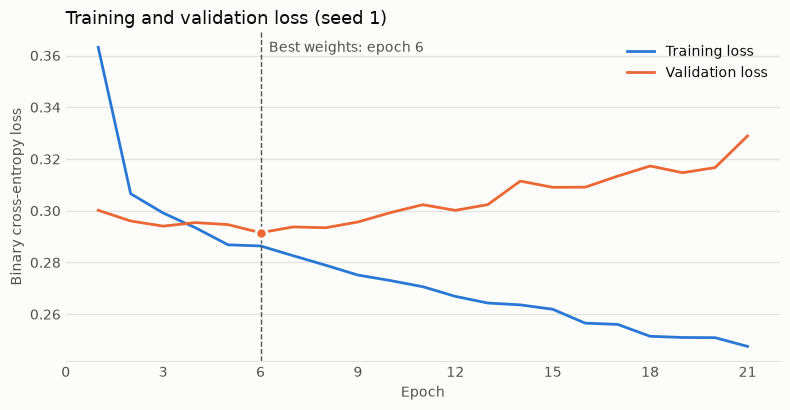

In [8]:
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

history = best_run['history']
epochs = range(1, history['epochs_run'] + 1)

fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(epochs, history['train_loss'], color=BLUE, linewidth=2, label='Training loss')
ax.plot(epochs, history['val_loss'], color=ORANGE, linewidth=2, label='Validation loss')
ax.axvline(history['best_epoch'], color=MUTED, linewidth=1, linestyle='--')
ax.scatter([history['best_epoch']], [history['best_val_loss']], color=ORANGE, s=64,
           edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate(f"Best weights: epoch {history['best_epoch']}", xy=(history['best_epoch'], 1), xycoords=('data', 'axes fraction'),
            xytext=(6, -14), textcoords='offset points', color=MUTED, fontsize=10)

ax.set_title(f"Training and validation loss (seed {best_run['seed']})", loc='left', color=INK, fontsize=13)
ax.set_xlabel('Epoch', color=MUTED)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel('Binary cross-entropy loss', color=MUTED)
ax.grid(axis='y', color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color(GRID)
ax.legend(frameon=False, labelcolor=INK, loc='upper right')
fig.tight_layout()
plt.show()

## 6. Evaluation on the test set

Up to here, the test set hasn't been used for training or for choosing a model.

Accuracy isn't enough on imbalanced data, so this also reports:
- **Precision:** of the people predicted >50K, how many really earn it
- **Recall:** of the people who really earn >50K, how many the model finds
- **F1:** a single score balancing precision and recall
- **ROC-AUC:** how well the model ranks high earners above others, at any threshold

In [9]:
def predict_probabilities(model, X):
    model.eval()
    with torch.no_grad():
        logits = model(torch.as_tensor(X, dtype=torch.float32))
        return torch.sigmoid(logits).view(-1).numpy()


def score(y_true, probabilities):
    predictions = (probabilities > THRESHOLD).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
    }


per_seed = pd.DataFrame([score(y_test, predict_probabilities(run['model'], X_test)) for run in runs],
                        index=[f"Seed {run['seed']}" for run in runs])
print('Network test results for every seed:')
display(per_seed.round(4))
print('Mean and standard deviation across seeds:')
display(per_seed.agg(['mean', 'std']).round(4))

Network test results for every seed:


,Accuracy,ROC-AUC,F1,Precision,Recall
Seed 0,0.8610,0.9154,0.6728,0.7577,0.6050
Seed 1,0.8622,0.9159,0.6854,0.7441,0.6352
Seed 2,0.8614,0.9167,0.6795,0.7491,0.6217
Seed 3,0.8616,0.9159,0.6827,0.7443,0.6305
Seed 4,0.8617,0.9142,0.6713,0.7651,0.5980


Mean and standard deviation across seeds:


,Accuracy,ROC-AUC,F1,Precision,Recall
mean,0.8616,0.9156,0.6783,0.7521,0.6181
std,0.0004,0.0009,0.0061,0.0091,0.0161


In [10]:
baselines = {
    'Always predict <=50K': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': LogisticRegression(max_iter=2000),
    'Gradient boosting (default settings)': HistGradientBoostingClassifier(random_state=0),
}

comparison = {}
for name, baseline in baselines.items():
    baseline.fit(X_train, y_train)
    comparison[name] = score(y_test, baseline.predict_proba(X_test)[:, 1])
comparison['PyTorch network (mean of 5 seeds)'] = per_seed.mean().to_dict()

print('All models use the same features and training data:')
display(pd.DataFrame(comparison).T.round(4))

All models use the same features and training data:


,Accuracy,ROC-AUC,F1,Precision,Recall
Always predict <=50K,0.7638,0.5000,0.0000,0.0000,0.0000
Logistic regression,0.8623,0.9154,0.6793,0.7549,0.6175
Gradient boosting (default settings),0.8724,0.9266,0.7086,0.7690,0.6570
PyTorch network (mean of 5 seeds),0.8616,0.9156,0.6783,0.7521,0.6181


In [11]:
final_probabilities = predict_probabilities(final_model, X_test)
final_predictions = (final_probabilities > THRESHOLD).astype(int)

print(f"Final model (seed {best_run['seed']}) on the test set:")
for metric, value in score(y_test, final_probabilities).items():
    print(f'  {metric:10s} {value:.4f}')

matrix = pd.DataFrame(confusion_matrix(y_test, final_predictions),
                      index=['Actual <=50K', 'Actual >50K'],
                      columns=['Predicted <=50K', 'Predicted >50K'])
print('\nConfusion matrix:')
display(matrix)

Final model (seed 1) on the test set:
  Accuracy   0.8622
  ROC-AUC    0.9159
  F1         0.6854
  Precision  0.7441
  Recall     0.6352

Confusion matrix:


,Predicted <=50K,Predicted >50K
Actual <=50K,11595,840
Actual >50K,1403,2443


### Results by group

The data records large income gaps between groups, and sex and race are model inputs. This table checks whether the model works equally well across those groups.

Small groups give noisy estimates, so their row counts matter when reading these numbers.

In [12]:
def group_report(column):
    rows = {}
    for group in sorted(df_test[column].unique()):
        mask = (df_test[column] == group).to_numpy()
        rows[group] = {
            'Rows': int(mask.sum()),
            'Actual >50K rate': y_test[mask].mean(),
            'Predicted >50K rate': final_predictions[mask].mean(),
            'Accuracy': accuracy_score(y_test[mask], final_predictions[mask]),
            'Recall': recall_score(y_test[mask], final_predictions[mask], zero_division=0),
        }
    return pd.DataFrame(rows).T.astype({'Rows': int}).round(3)


display(group_report('gender'))
display(group_report('race'))

,Rows,Actual >50K rate,Predicted >50K rate,Accuracy,Recall
Female,5421,0.109,0.078,0.934,0.553
Male,10860,0.300,0.263,0.827,0.650


,Rows,Actual >50K rate,Predicted >50K rate,Accuracy,Recall
Amer-Indian-Eskimo,159,0.119,0.069,0.925,0.474
Asian-Pac-Islander,480,0.277,0.229,0.835,0.617
Black,1561,0.115,0.084,0.922,0.525
Other,135,0.185,0.089,0.889,0.440
White,13946,0.250,0.216,0.856,0.644


## 7. Save the model and make predictions

The file stores the network's weights together with the preprocessing statistics, because new data has to be transformed exactly as the training data was.

It holds only tensors and basic Python types, so it loads with `weights_only=True`, PyTorch's safer loading mode.

In [13]:
MODEL_PATH.parent.mkdir(exist_ok=True)
torch.save({
    'state_dict': final_model.state_dict(),
    'input_size': X_train.shape[1],
    'preprocessor': preprocessor.to_dict(),
}, MODEL_PATH)


def load_model(path=MODEL_PATH):
    checkpoint = torch.load(path, weights_only=True)
    model = IncomeClassifier(checkpoint['input_size'])
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    return model, IncomePreprocessor.from_dict(checkpoint['preprocessor'])


def predict_income(people, path=MODEL_PATH):
    """Predict income brackets for a list of dicts containing the model's feature columns."""
    model, saved_preprocessor = load_model(path)
    df = clean_features(pd.DataFrame(people))
    probabilities = predict_probabilities(model, saved_preprocessor.transform(df))
    return pd.DataFrame({
        'Probability of >50K': probabilities.round(3),
        'Prediction': np.where(probabilities > THRESHOLD, '>50K', '<=50K'),
    })


# The reloaded model must reproduce the same test predictions
reloaded_model, reloaded_preprocessor = load_model()
reloaded_probabilities = predict_probabilities(reloaded_model, reloaded_preprocessor.transform(df_test))
assert np.allclose(reloaded_probabilities, final_probabilities), 'Reloaded model gives different predictions'
print(f'Saved {MODEL_PATH.as_posix()} ({MODEL_PATH.stat().st_size / 1024:.0f} KB) and verified that it reloads correctly')

Saved model/income_classifier.pt (121 KB) and verified that it reloads correctly


In [14]:
# Fictional example people. Edit these values to try your own.
examples = [
    {'age': 45, 'workclass': 'Private', 'education_num': 16, 'marital_status': 'Married-civ-spouse',
     'occupation': 'Exec-managerial', 'relationship': 'Husband', 'race': 'White', 'gender': 'Male',
     'capital_gain': 15000, 'capital_loss': 0, 'hours_per_week': 50, 'native_country': 'United-States'},
    {'age': 22, 'workclass': 'Private', 'education_num': 9, 'marital_status': 'Never-married',
     'occupation': 'Other-service', 'relationship': 'Own-child', 'race': 'White', 'gender': 'Female',
     'capital_gain': 0, 'capital_loss': 0, 'hours_per_week': 25, 'native_country': 'United-States'},
]
predict_income(examples)

,Probability of >50K,Prediction
0,0.999,>50K
1,0.000,<=50K


## 8. Limitations

- **The data is old.** It comes from the 1994 US Census, so the $50K line and the patterns behind it are out of date.
- **It reflects historical inequality.** The model uses sex and race as inputs and can reproduce those patterns, so it shouldn't be used for real decisions about people, such as hiring or lending.
- **The network isn't the best model here.** It ties logistic regression on these features, and gradient boosting scores higher, which is typical for tabular data. The network was built to learn PyTorch, and it is reported next to these baselines on purpose.
- **Tuning is limited.** A few settings were compared on validation data, but there was no exhaustive search.